In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
# ============================================================
# RUNTIME BOOTSTRAP — VS Code + Google Colab compatible
# ============================================================
# This notebook is intended to work when opened in VS Code and attached
# to a Colab/Jupyter kernel. Google Drive is mounted only when the kernel
# actually provides google.colab.

import os
import sys
import importlib.util

RUNNING_IN_COLAB = (
    importlib.util.find_spec('google.colab') is not None
    and os.path.isdir('/content')
)

AUTO_MOUNT_GOOGLE_DRIVE = True

if RUNNING_IN_COLAB and AUTO_MOUNT_GOOGLE_DRIVE:
    drive_root = '/content/drive/MyDrive'
    if not os.path.isdir(drive_root):
        try:
            from google.colab import drive
            drive.mount('/content/drive', force_remount=False)
        except Exception as exc:
            print(
                'Google Drive could not be mounted automatically from this frontend.\n'
                'You can either mount Drive from a Colab tab that uses the same runtime, '
                'or set PHYSIOGNOMY_INPUT_DIR / PHYSIOGNOMY_OUTPUT_DIR to paths that are '
                'visible to the connected kernel.\n'
                f'Detail: {exc!r}'
            )

print('Running in Colab kernel:', RUNNING_IN_COLAB)
print('Python executable:', sys.executable)


Running in Colab kernel: True
Python executable: /usr/bin/python3


In [3]:
import os
import sys
import glob
import cv2
import json
import math
import traceback
import subprocess
import importlib
from pathlib import Path
from PIL import Image

import numpy as np
import pandas as pd
import torch
from tqdm.auto import tqdm
from IPython.display import display


# ============================================================
# Dependency bootstrap
# Works in Colab notebooks and in VS Code/Jupyter without !pip
# ============================================================

def pip_install(*packages):
    subprocess.check_call([
        sys.executable,
        '-m',
        'pip',
        'install',
        '-q',
        '-U',
        *packages,
    ])
    importlib.invalidate_caches()


try:
    import insightface
    from insightface.app import FaceAnalysis
except ImportError:
    ort_pkg = 'onnxruntime-gpu' if torch.cuda.is_available() else 'onnxruntime'
    pip_install('insightface', ort_pkg)
    import insightface
    from insightface.app import FaceAnalysis


try:
    import facexlib
    from facexlib.parsing import init_parsing_model
    from facexlib.utils.misc import img2tensor
except ImportError:
    pip_install('facexlib')
    import facexlib
    from facexlib.parsing import init_parsing_model
    from facexlib.utils.misc import img2tensor


from torchvision.transforms.functional import normalize


# ============================================================
# Paths
# ============================================================
# When VS Code is attached to a Colab kernel, these paths refer to the
# remote Colab filesystem. You can override them without editing the
# notebook by setting:
#   PHYSIOGNOMY_INPUT_DIR
#   PHYSIOGNOMY_OUTPUT_DIR
#
# Example in a VS Code notebook cell:
#   %env PHYSIOGNOMY_INPUT_DIR=/content/drive/MyDrive/Dataset/Humans

if RUNNING_IN_COLAB:
    default_input_dir = '/content/drive/MyDrive/Dataset/Humans'
    default_output_dir = '/content/drive/MyDrive/Dataset/Humans_Output'
else:
    default_input_dir = str(Path.cwd() / 'Dataset' / 'Humans')
    default_output_dir = str(Path.cwd() / 'Dataset' / 'Humans_Output')

INPUT_DIR = os.environ.get('PHYSIOGNOMY_INPUT_DIR', default_input_dir)
OUTPUT_DIR = os.environ.get('PHYSIOGNOMY_OUTPUT_DIR', default_output_dir)

IMAGES_OUT_DIR = os.path.join(OUTPUT_DIR, 'images')
MASKS_OUT_DIR = os.path.join(OUTPUT_DIR, 'masks')
TXT_OUT_DIR = os.path.join(OUTPUT_DIR, 'txt')
ALIGNED_OUT_DIR = os.path.join(OUTPUT_DIR, 'aligned_debug')
CSV_PATH = os.path.join(OUTPUT_DIR, 'faces_full_features.csv')
ERROR_CSV_PATH = os.path.join(OUTPUT_DIR, 'processing_errors.csv')

if not os.path.isdir(INPUT_DIR):
    raise FileNotFoundError(
        f'INPUT_DIR does not exist: {INPUT_DIR}\n'
        'If you are using VS Code with a Colab kernel, make sure Google Drive is mounted '
        'or set PHYSIOGNOMY_INPUT_DIR to a path visible to that kernel.'
    )


# -----------------------------------------------------------------
# Robust image loading + multi-pass SCRFD recovery
# Pass 1 = normal fast path.
# Pass 2/3 are only used when the previous pass detects 0 faces.
# -----------------------------------------------------------------
DETECTION_PASSES = [
    {'det_size': 640,  'det_thresh': 0.25},
    {'det_size': 1024, 'det_thresh': 0.15},
    {'det_size': 1280, 'det_thresh': 0.05},
]

# Normalize extreme image sizes before SCRFD.
# The coordinates are mapped back to the EXIF-corrected original image.
ROBUST_MIN_SHORT_SIDE = 640
ROBUST_MAX_LONG_SIDE = 2560
ROBUST_MAX_UPSCALE = 2.0

ALIGN_SIZE = 512
MIN_FACE_SIZE_PX = 60        # QC only by default
LOW_CONF_WARN = 0.45         # QC warning, not detector threshold
MAX_ABS_ROLL_DEG = 25.0      # QC warning
MAX_YAW_PROXY = 0.35         # QC warning; approximate, NOT a true yaw angle
STRICT_QC = False            # True => reject qc_pass=False samples
SAVE_ALIGNED_FACE = False    # useful for debugging but consumes storage
CHECKPOINT_EVERY = 500       # protect long runs from losing all records

for d in [OUTPUT_DIR, IMAGES_OUT_DIR, MASKS_OUT_DIR, TXT_OUT_DIR]:
    os.makedirs(d, exist_ok=True)
if SAVE_ALIGNED_FACE:
    os.makedirs(ALIGNED_OUT_DIR, exist_ok=True)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE)
print('InsightFace:', insightface.__version__)
print('Detection passes:', DETECTION_PASSES)
print('Input:', INPUT_DIR)
print('Output:', OUTPUT_DIR)


Device: cuda
InsightFace: 2.0
Detection passes: [{'det_size': 640, 'det_thresh': 0.25}, {'det_size': 1024, 'det_thresh': 0.15}, {'det_size': 1280, 'det_thresh': 0.05}]
Input: /content/drive/MyDrive/Dataset/Humans
Output: /content/drive/MyDrive/Dataset/Humans_Output


In [4]:
providers = (
    ['CUDAExecutionProvider', 'CPUExecutionProvider']
    if torch.cuda.is_available()
    else ['CPUExecutionProvider']
)

app = FaceAnalysis(
    name='buffalo_l',
    providers=providers,
    allowed_modules=['detection', 'landmark_2d_106']
)

_first_pass = DETECTION_PASSES[0]

app.prepare(
    ctx_id=0 if torch.cuda.is_available() else -1,
    det_size=(_first_pass['det_size'], _first_pass['det_size']),
    det_thresh=_first_pass['det_thresh'],
)

parser = init_parsing_model(
    model_name='bisenet',
    device=DEVICE,
)
parser.eval()

PARSING_LABELS = {
    0: 'background', 1: 'skin', 2: 'left_brow', 3: 'right_brow',
    4: 'left_eye', 5: 'right_eye', 6: 'eyeglasses',
    7: 'left_ear', 8: 'right_ear', 9: 'earring', 10: 'nose',
    11: 'mouth', 12: 'upper_lip', 13: 'lower_lip', 14: 'neck',
    15: 'necklace', 16: 'cloth', 17: 'hair', 18: 'hat',
}

print('InsightFace modules:', list(app.models.keys()))
print('Face parser ready:', parser.__class__.__name__)
print('Providers:', providers)

InsightFace modules: ['landmark_2d_106', 'detection']
Face parser ready: BiSeNet
Providers: ['CUDAExecutionProvider', 'CPUExecutionProvider']


In [5]:
def safe_float(v, ndigits=6):
    if v is None:
        return np.nan
    try:
        if np.isnan(v):
            return np.nan
    except Exception:
        pass
    return round(float(v), ndigits)


def clean_binary_mask(mask, min_area=24, kernel_size=3):
    """Remove tiny isolated components and lightly close holes."""
    m = mask.astype(np.uint8)
    if kernel_size > 1:
        k = np.ones((kernel_size, kernel_size), np.uint8)
        m = cv2.morphologyEx(m, cv2.MORPH_CLOSE, k)
    n, labels, stats, _ = cv2.connectedComponentsWithStats(m, connectivity=8)
    out = np.zeros_like(m)
    for i in range(1, n):
        if stats[i, cv2.CC_STAT_AREA] >= min_area:
            out[labels == i] = 1
    return out.astype(bool)


def mask_bbox(mask):
    ys, xs = np.where(mask > 0)
    if len(xs) == 0:
        return None
    return int(xs.min()), int(ys.min()), int(xs.max()), int(ys.max())


def mask_center(mask):
    ys, xs = np.where(mask > 0)
    if len(xs) == 0:
        return None
    return float(xs.mean()), float(ys.mean())


def mask_stats(mask):
    ys, xs = np.where(mask > 0)
    if len(xs) == 0:
        return {
            'area_px': 0,
            'bbox_x1': np.nan, 'bbox_y1': np.nan,
            'bbox_x2': np.nan, 'bbox_y2': np.nan,
            'cx': np.nan, 'cy': np.nan,
        }
    return {
        'area_px': int(len(xs)),
        'bbox_x1': int(xs.min()), 'bbox_y1': int(ys.min()),
        'bbox_x2': int(xs.max()), 'bbox_y2': int(ys.max()),
        'cx': float(xs.mean()), 'cy': float(ys.mean()),
    }


# Canonical 5-point template for parsing, not for face-recognition embeddings.
# It deliberately leaves context above/below the face for forehead/chin parsing.
CANONICAL_KPS_512 = np.array([
    [168.0, 190.0],  # eye 1
    [344.0, 190.0],  # eye 2
    [256.0, 278.0],  # nose
    [194.0, 360.0],  # mouth corner 1
    [318.0, 360.0],  # mouth corner 2
], dtype=np.float32)


def apply_affine_to_points(points, M):
    pts = np.asarray(points, dtype=np.float32)
    ones = np.ones((len(pts), 1), dtype=np.float32)
    homo = np.hstack([pts, ones])
    return (homo @ M.T).astype(np.float32)


def align_face_5pt(img, kps5, lm106=None, output_size=512):
    """Similarity-align face from InsightFace 5 keypoints to canonical parsing canvas."""
    src = np.asarray(kps5, dtype=np.float32)
    if src.shape != (5, 2) or not np.isfinite(src).all():
        raise ValueError(f'Invalid kps5 shape/value: {src.shape}')

    dst = CANONICAL_KPS_512 * (float(output_size) / 512.0)
    M, inliers = cv2.estimateAffinePartial2D(src, dst, method=cv2.LMEDS)
    if M is None:
        # fallback: two eyes + nose
        M = cv2.getAffineTransform(src[:3], dst[:3])

    aligned = cv2.warpAffine(
        img, M, (output_size, output_size),
        flags=cv2.INTER_LINEAR,
        borderMode=cv2.BORDER_CONSTANT,
        borderValue=(0, 0, 0),
    )
    M_inv = cv2.invertAffineTransform(M)
    kps_aligned = apply_affine_to_points(src, M)
    lm_aligned = apply_affine_to_points(lm106, M) if lm106 is not None else None
    return aligned, M.astype(np.float32), M_inv.astype(np.float32), kps_aligned, lm_aligned


def run_face_parsing(aligned_face):
    """Return ALIGN_SIZE x ALIGN_SIZE parsing mask with values 0..18."""
    resized = cv2.resize(aligned_face, (ALIGN_SIZE, ALIGN_SIZE), interpolation=cv2.INTER_LINEAR)
    t = img2tensor(resized.astype('float32') / 255.0, bgr2rgb=True, float32=True)
    normalize(t, (0.485, 0.456, 0.406), (0.229, 0.224, 0.225), inplace=True)
    t = t.unsqueeze(0).to(DEVICE)
    with torch.inference_mode():
        out = parser(t)[0]
        parsing = out.squeeze(0).detach().cpu().numpy().argmax(0).astype(np.uint8)
    return parsing


def compute_pose_qc(kps5, bbox, det_score):
    """Cheap QC proxies. yaw_proxy is NOT a calibrated yaw angle."""
    k = np.asarray(kps5, dtype=np.float32)
    eye_l, eye_r, nose = k[0], k[1], k[2]
    dx, dy = eye_r - eye_l
    eye_dist = float(np.hypot(dx, dy))
    roll_deg = float(np.degrees(np.arctan2(dy, dx)))
    eye_mid = (eye_l + eye_r) / 2.0
    yaw_proxy = float(abs(nose[0] - eye_mid[0]) / max(eye_dist, 1e-6))

    x1, y1, x2, y2 = map(float, bbox[:4])
    min_face_side = float(min(x2 - x1, y2 - y1))

    reasons = []
    if float(det_score) < LOW_CONF_WARN:
        reasons.append('low_det_conf')
    if min_face_side < MIN_FACE_SIZE_PX:
        reasons.append('small_face')
    if abs(roll_deg) > MAX_ABS_ROLL_DEG:
        reasons.append('large_roll')
    if yaw_proxy > MAX_YAW_PROXY:
        reasons.append('large_yaw_proxy')

    return {
        'roll_deg': roll_deg,
        'yaw_proxy': yaw_proxy,
        'eye_distance_px': eye_dist,
        'min_face_side_px': min_face_side,
        'qc_pass': len(reasons) == 0,
        'qc_reasons': '|'.join(reasons) if reasons else 'ok',
    }


def build_semantic_regions(parsing):
    """
    Direct classes come from BiSeNet.
    Forehead/cheeks/chin are derived from skin + semantic anchors.
    Since the face is already aligned, these anchors are much more stable than raw crop coordinates.
    """
    h, w = parsing.shape
    yy, xx = np.mgrid[0:h, 0:w]

    skin = clean_binary_mask(parsing == 1, min_area=120, kernel_size=3)
    direct = {
        'left_brow': clean_binary_mask(parsing == 2, min_area=16),
        'right_brow': clean_binary_mask(parsing == 3, min_area=16),
        'left_eye': clean_binary_mask(parsing == 4, min_area=12),
        'right_eye': clean_binary_mask(parsing == 5, min_area=12),
        'left_ear': clean_binary_mask(parsing == 7, min_area=20),
        'right_ear': clean_binary_mask(parsing == 8, min_area=20),
        'nose': clean_binary_mask(parsing == 10, min_area=20),
        'mouth': clean_binary_mask(np.isin(parsing, [11, 12, 13]), min_area=20),
    }

    face_support = np.isin(parsing, [1,2,3,4,5,6,7,8,10,11,12,13])
    fb = mask_bbox(face_support)
    if fb is None:
        # canonical fallback; should be rare if parsing succeeded
        fx1, fy1, fx2, fy2 = int(0.12*w), int(0.08*h), int(0.88*w), int(0.94*h)
    else:
        fx1, fy1, fx2, fy2 = fb

    fw = max(fx2 - fx1 + 1, 1)
    fh = max(fy2 - fy1 + 1, 1)

    brows = direct['left_brow'] | direct['right_brow']
    eyes = direct['left_eye'] | direct['right_eye']
    brow_box = mask_bbox(brows)
    eye_box = mask_bbox(eyes)
    mouth_box = mask_bbox(direct['mouth'])
    nose_center = mask_center(direct['nose'])

    brow_top = brow_box[1] if brow_box else int(fy1 + 0.34*fh)
    eye_bottom = eye_box[3] if eye_box else int(fy1 + 0.48*fh)
    mouth_top = mouth_box[1] if mouth_box else int(fy1 + 0.67*fh)
    mouth_bottom = mouth_box[3] if mouth_box else int(fy1 + 0.76*fh)
    nose_cx = nose_center[0] if nose_center else (fx1 + fx2) / 2.0

    # Dynamic regions anchored to semantic parts, then intersected with skin.
    forehead = (
        skin
        & (yy >= fy1)
        & (yy <= max(fy1, brow_top - int(0.015*fh)))
        & (xx >= fx1 + int(0.14*fw))
        & (xx <= fx2 - int(0.14*fw))
    )

    cheek_y1 = min(fy2, eye_bottom + int(0.02*fh))
    cheek_y2 = max(cheek_y1, mouth_top - int(0.015*fh))
    side_gap = int(0.035*fw)
    left_cheek = (
        skin
        & (yy >= cheek_y1) & (yy <= cheek_y2)
        & (xx >= fx1 + int(0.06*fw))
        & (xx <= int(nose_cx) - side_gap)
    )
    right_cheek = (
        skin
        & (yy >= cheek_y1) & (yy <= cheek_y2)
        & (xx >= int(nose_cx) + side_gap)
        & (xx <= fx2 - int(0.06*fw))
    )

    chin = (
        skin
        & (yy >= mouth_bottom + int(0.02*fh))
        & (yy <= fy2)
        & (xx >= fx1 + int(0.24*fw))
        & (xx <= fx2 - int(0.24*fw))
    )

    regions = {
        'forehead': clean_binary_mask(forehead, min_area=24),
        **direct,
        'chin': clean_binary_mask(chin, min_area=24),
        'left_cheek': clean_binary_mask(left_cheek, min_area=24),
        'right_cheek': clean_binary_mask(right_cheek, min_area=24),
    }
    return regions, face_support.astype(bool)


def robust_band_span(points, y_low, y_high):
    """Robust horizontal span after alignment; avoids detector bbox as geometry source."""
    pts = np.asarray(points, dtype=np.float32)
    if len(pts) < 4:
        return np.nan
    y0, y1 = np.quantile(pts[:, 1], [0.02, 0.98])
    h = max(float(y1 - y0), 1e-6)
    yn = (pts[:, 1] - y0) / h
    band = pts[(yn >= y_low) & (yn < y_high)]
    if len(band) < 2:
        return np.nan
    lo, hi = np.quantile(band[:, 0], [0.05, 0.95])
    return float(hi - lo)


def compute_face_geometry(lm106_aligned, qc_pass=True):
    """Compute face geometry ratios from aligned landmarks."""
    lm = np.asarray(lm106_aligned, dtype=np.float32)
    x_lo, x_hi = np.quantile(lm[:, 0], [0.02, 0.98])
    y_lo, y_hi = np.quantile(lm[:, 1], [0.02, 0.98])
    face_w = max(float(x_hi - x_lo), 1e-6)
    face_h = max(float(y_hi - y_lo), 1e-6)

    upper_w = robust_band_span(lm, 0.08, 0.30)
    cheek_w = robust_band_span(lm, 0.30, 0.64)
    jaw_w = robust_band_span(lm, 0.66, 0.94)
    if np.isnan(upper_w): upper_w = face_w * 0.80
    if np.isnan(cheek_w): cheek_w = face_w * 0.95
    if np.isnan(jaw_w): jaw_w = face_w * 0.72

    hw = face_h / face_w
    upper_cheek = upper_w / max(cheek_w, 1e-6)
    jaw_cheek = jaw_w / max(cheek_w, 1e-6)

    return {
        'face_width_px_aligned': face_w,
        'face_height_px_aligned': face_h,
        'face_height_width_ratio': hw,
        'upper_face_width_px_aligned': upper_w,
        'cheek_width_px_aligned': cheek_w,
        'jaw_width_px_aligned': jaw_w,
        'upper_to_cheek_ratio': upper_cheek,
        'jaw_to_cheek_ratio': jaw_cheek,
    }


REGION_COLORS = {
    'forehead': (255, 220, 40),
    'left_brow': (0, 180, 255), 'right_brow': (0, 180, 255),
    'left_eye': (0, 255, 0), 'right_eye': (0, 255, 0),
    'nose': (255, 120, 0), 'mouth': (255, 0, 255),
    'left_ear': (0, 255, 255), 'right_ear': (0, 255, 255),
    'chin': (180, 80, 255),
    'left_cheek': (255, 140, 140), 'right_cheek': (255, 140, 140),
}


def warp_mask_to_original(mask_aligned, M_inv, out_w, out_h):
    return cv2.warpAffine(
        mask_aligned.astype(np.uint8), M_inv, (out_w, out_h),
        flags=cv2.INTER_NEAREST,
        borderMode=cv2.BORDER_CONSTANT,
        borderValue=0,
    ).astype(bool)


def overlay_regions_on_original(img, regions_aligned, M_inv, alpha=0.30):
    """Inverse-warp aligned region masks to original image."""
    H, W = img.shape[:2]
    overlay = img.copy()
    full_id_mask = np.zeros((H, W), dtype=np.uint8)
    full_masks = {}

    for rid, (name, m_aligned) in enumerate(regions_aligned.items(), start=1):
        m = warp_mask_to_original(m_aligned, M_inv, W, H)
        full_masks[name] = m
        if not np.any(m):
            continue
        color = np.array(REGION_COLORS[name], dtype=np.float32)
        overlay[m] = (overlay[m].astype(np.float32)*(1-alpha) + color*alpha).astype(np.uint8)
        full_id_mask[m] = rid

    return overlay, full_id_mask, full_masks


def draw_landmarks_and_bbox(img, bbox, lm106, qc_pass):
    out = img.copy()
    x1, y1, x2, y2 = np.asarray(bbox[:4]).astype(int)
    box_color = (0,255,0) if qc_pass else (0,165,255)
    cv2.rectangle(out, (x1,y1), (x2,y2), box_color, 2)
    for x, y in np.asarray(lm106).astype(int):
        cv2.circle(out, (x,y), 1, (0,0,255), -1)
    label = f'QC:{"PASS" if qc_pass else "WARN"}'
    cv2.putText(out, label, (x1, max(20, y1-10)), cv2.FONT_HERSHEY_SIMPLEX, 0.65, box_color, 2)
    return out


def write_txt(path, record, region_records, kps5, lm106):
    with open(path, 'w', encoding='utf-8') as f:
        base_keys = [
            'image','image_width','image_height','num_faces_detected','det_score',
            'bbox_x1','bbox_y1','bbox_x2','bbox_y2',
            'roll_deg','yaw_proxy','eye_distance_px','min_face_side_px','qc_pass','qc_reasons',
            'face_height_width_ratio','upper_to_cheek_ratio','jaw_to_cheek_ratio',
        ]
        for k in base_keys:
            f.write(f'{k}={record.get(k)}\n')

        f.write('\n[semantic_regions]\n')
        for name, rr in region_records.items():
            f.write(
                f'{name}: area_px={rr["area_px"]}, area_ratio_face={rr["area_ratio_face"]}, '
                f'bbox=({rr["bbox_x1"]},{rr["bbox_y1"]},{rr["bbox_x2"]},{rr["bbox_y2"]}), '
                f'centroid=({rr["cx"]},{rr["cy"]})\n'
            )

        f.write('\n[kps5_original]\n')
        for i, (x,y) in enumerate(np.asarray(kps5)):
            f.write(f'{i}={float(x):.4f},{float(y):.4f}\n')

        f.write('\n[landmark_2d_106_original]\n')
        for i, (x,y) in enumerate(np.asarray(lm106)):
            f.write(f'{i}={float(x):.4f},{float(y):.4f}\n')


# ============================================================
# ROBUST IMAGE LOADING + MULTI-PASS SCRFD
# ============================================================

def _read_exif_orientation(path):
    """Read EXIF orientation (274). Return 1 when absent/unreadable."""
    try:
        with Image.open(path) as pil_img:
            exif = pil_img.getexif()
            return int(exif.get(274, 1))
    except Exception:
        return 1


def _apply_exif_orientation_bgr(img, orientation):
    """
    Apply standard EXIF orientation to an OpenCV BGR image.
    Supports mirrored orientations as well as rotations.
    """
    if img is None:
        return None

    if orientation == 2:      # mirrored horizontal
        img = cv2.flip(img, 1)
    elif orientation == 3:    # 180
        img = cv2.rotate(img, cv2.ROTATE_180)
    elif orientation == 4:    # mirrored vertical
        img = cv2.flip(img, 0)
    elif orientation == 5:    # transpose
        img = cv2.transpose(img)
    elif orientation == 6:    # 90 CW
        img = cv2.rotate(img, cv2.ROTATE_90_CLOCKWISE)
    elif orientation == 7:    # transverse
        img = cv2.transpose(img)
        img = cv2.flip(img, -1)
    elif orientation == 8:    # 90 CCW
        img = cv2.rotate(img, cv2.ROTATE_90_COUNTERCLOCKWISE)

    return img


def load_image_robust(path):
    """
    Robust loader requested for this pipeline:
      np.fromfile -> cv2.imdecode -> EXIF orientation correction.

    np.fromfile + imdecode is more robust than cv2.imread for
    non-ASCII/Unicode paths on some systems.
    """
    try:
        raw = np.fromfile(path, dtype=np.uint8)
        if raw.size == 0:
            return None

        img = cv2.imdecode(raw, cv2.IMREAD_COLOR)
        if img is None:
            return None

        orientation = _read_exif_orientation(path)
        img = _apply_exif_orientation_bgr(img, orientation)
        return img

    except Exception:
        return None


def normalize_detection_image(img):
    """
    Upscale small images and downscale extremely large images before SCRFD.

    Returns
    -------
    work_img : image used for detection
    scale    : work_img coordinate / original coordinate
               Divide detected coordinates by `scale` to map them back.
    mode     : 'upscale', 'downscale', or 'none'
    """
    h, w = img.shape[:2]
    short_side = min(h, w)
    long_side = max(h, w)

    scale = 1.0
    mode = 'none'

    if short_side < ROBUST_MIN_SHORT_SIDE:
        scale = min(
            ROBUST_MIN_SHORT_SIDE / max(short_side, 1),
            ROBUST_MAX_UPSCALE
        )
        mode = 'upscale'

    # If the image is extremely large, prefer downscaling.
    # This branch intentionally overrides an upscale request only when needed.
    if long_side * scale > ROBUST_MAX_LONG_SIDE:
        scale = ROBUST_MAX_LONG_SIDE / max(long_side, 1)
        mode = 'downscale' if scale < 1.0 else mode

    if abs(scale - 1.0) < 1e-6:
        return img, 1.0, 'none'

    new_w = max(1, int(round(w * scale)))
    new_h = max(1, int(round(h * scale)))

    interpolation = cv2.INTER_CUBIC if scale > 1.0 else cv2.INTER_AREA
    work = cv2.resize(img, (new_w, new_h), interpolation=interpolation)

    return work, float(scale), mode


def _set_scrfd_pass(app, det_size, det_thresh):
    """
    Change SCRFD input size / candidate threshold without reloading ONNX models.
    """
    detector = getattr(app, 'det_model', None)

    if detector is None:
        detector = app.models.get('detection', None)

    if detector is None:
        raise RuntimeError('InsightFace detection model is unavailable.')

    detector.input_size = (int(det_size), int(det_size))
    detector.det_thresh = float(det_thresh)


def _map_face_geometry_to_original(face, scale):
    """
    Extract bbox / 5-point landmarks / 106 landmarks and map coordinates
    from the normalized detection image back to the EXIF-corrected original.
    """
    if scale <= 0:
        raise ValueError(f'Invalid detection scale: {scale}')

    bbox = np.asarray(face.bbox, dtype=np.float32) / scale

    kps5 = getattr(face, 'kps', None)
    if kps5 is None:
        return None
    kps5 = np.asarray(kps5, dtype=np.float32) / scale

    lm106 = getattr(face, 'landmark_2d_106', None)
    if lm106 is None or len(lm106) != 106:
        return None
    lm106 = np.asarray(lm106, dtype=np.float32) / scale

    return bbox, kps5, lm106


def robust_detect_single_face(app, img):
    """
    Multi-pass SCRFD:
        640 / 0.25
        1024 / 0.15
        1280 / 0.05

    Rules
    -----
    - Exactly one face is required.
    - >1 face at any pass => immediate multi_face rejection.
    - 0 face => escalate to the next pass.
    - Pass 2/3 success => status='recovered'.
    - All passes fail => status='robust_miss'.

    Important:
    0.05 is intentionally only a last-resort candidate threshold.
    QC remains a separate downstream safeguard.
    """
    det_img, scale, resize_mode = normalize_detection_image(img)
    dh, dw = det_img.shape[:2]

    history = []
    last_error = None
    saw_missing_landmarks = False

    for pass_idx, cfg in enumerate(DETECTION_PASSES, start=1):
        det_size = int(cfg['det_size'])
        det_thresh = float(cfg['det_thresh'])

        try:
            _set_scrfd_pass(app, det_size, det_thresh)
            faces = app.get(det_img)

        except Exception as e:
            last_error = e
            history.append({
                'pass': pass_idx,
                'det_size': det_size,
                'det_thresh': det_thresh,
                'num_faces': -1,
                'result': 'inference_error',
            })
            continue

        n_faces = len(faces)

        history.append({
            'pass': pass_idx,
            'det_size': det_size,
            'det_thresh': det_thresh,
            'num_faces': n_faces,
            'result': 'candidate',
        })

        # Hard rule: if we can see multiple faces, reject the image.
        if n_faces > 1:
            history[-1]['result'] = 'multi_face'
            return {
                'status': 'multi_face',
                'face': None,
                'bbox': None,
                'kps5': None,
                'lm106': None,
                'pass_index': pass_idx,
                'det_size_used': det_size,
                'det_thresh_used': det_thresh,
                'was_recovered': False,
                'detection_scale': scale,
                'resize_mode': resize_mode,
                'detection_width': dw,
                'detection_height': dh,
                'history': history,
                'error': None,
            }

        if n_faces == 0:
            history[-1]['result'] = 'no_face'
            continue

        # n_faces == 1
        face = faces[0]
        mapped = _map_face_geometry_to_original(face, scale)

        if mapped is None:
            saw_missing_landmarks = True
            history[-1]['result'] = 'missing_landmarks'
            # Try a more robust pass before giving up.
            continue

        bbox, kps5, lm106 = mapped

        status = 'normal_success' if pass_idx == 1 else 'recovered'
        history[-1]['result'] = status

        return {
            'status': status,
            'face': face,
            'bbox': bbox,
            'kps5': kps5,
            'lm106': lm106,
            'pass_index': pass_idx,
            'det_size_used': det_size,
            'det_thresh_used': det_thresh,
            'was_recovered': pass_idx > 1,
            'detection_scale': scale,
            'resize_mode': resize_mode,
            'detection_width': dw,
            'detection_height': dh,
            'history': history,
            'error': None,
        }

    # No successful pass.
    if saw_missing_landmarks:
        miss_reason = 'missing_landmarks'
    elif last_error is not None and all(h['num_faces'] == -1 for h in history):
        miss_reason = 'inference_error'
    else:
        miss_reason = 'no_face'

    return {
        'status': 'robust_miss',
        'miss_reason': miss_reason,
        'face': None,
        'bbox': None,
        'kps5': None,
        'lm106': None,
        'pass_index': len(DETECTION_PASSES),
        'det_size_used': DETECTION_PASSES[-1]['det_size'],
        'det_thresh_used': DETECTION_PASSES[-1]['det_thresh'],
        'was_recovered': False,
        'detection_scale': scale,
        'resize_mode': resize_mode,
        'detection_width': dw,
        'detection_height': dh,
        'history': history,
        'error': last_error,
    }


In [6]:
# ============================================================
# PROCESS DATASET
# Hard rule: only exactly 1 detected face is accepted
# ============================================================

image_exts = {'.jpg', '.jpeg', '.png', '.bmp'}

image_paths = sorted([
    str(p)
    for p in Path(INPUT_DIR).rglob('*')
    if p.is_file() and p.suffix.lower() in image_exts
])


# ============================================================
# Statistics
# ============================================================

stats = {
    'total': len(image_paths),

    'accepted_1_face': 0,
    'accepted_qc_warn': 0,
    'normal_success': 0,
    'recovered': 0,
    'robust_miss': 0,

    'skip_0_face': 0,
    'skip_multi_face': 0,
    'skip_read_error': 0,
    'skip_missing_106': 0,
    'skip_alignment_error': 0,
    'skip_parse_error': 0,
    'skip_strict_qc': 0,

    'inference_error': 0,
    'save_error': 0,
}


records = []
error_records = []


region_names = [
    'forehead',
    'left_brow',
    'right_brow',
    'left_eye',
    'right_eye',
    'nose',
    'mouth',
    'left_ear',
    'right_ear',
    'chin',
    'left_cheek',
    'right_cheek'
]


# ============================================================
# Helpers
# ============================================================

def log_error(img_path, stage, exc=None, detail=None):
    """
    Save processing errors for later inspection.
    """

    error_records.append({
        'image_path': img_path,
        'stage': stage,
        'error': repr(exc) if exc is not None else '',
        'detail': detail or '',
    })


def valid_number(x):
    """
    Check whether x is a valid numeric value.
    """
    try:
        return not pd.isna(x)
    except Exception:
        return False


def safe_ratio(a, b):
    """
    Safe division.
    """
    if (
        a is None or
        b is None or
        not valid_number(a) or
        not valid_number(b) or
        abs(float(b)) < 1e-6
    ):
        return np.nan

    return safe_float(float(a) / float(b))


def get_region_width(region_stats):
    """
    Width from region bounding box.
    """

    x1 = region_stats.get('bbox_x1', np.nan)
    x2 = region_stats.get('bbox_x2', np.nan)

    if not valid_number(x1) or not valid_number(x2):
        return np.nan

    return max(float(x2) - float(x1), 0.0)


def get_region_height(region_stats):
    """
    Height from region bounding box.
    """

    y1 = region_stats.get('bbox_y1', np.nan)
    y2 = region_stats.get('bbox_y2', np.nan)

    if not valid_number(y1) or not valid_number(y2):
        return np.nan

    return max(float(y2) - float(y1), 0.0)


def get_distance(x1, y1, x2, y2):
    """
    Euclidean distance.
    """

    if not all(valid_number(v) for v in [x1, y1, x2, y2]):
        return np.nan

    return float(np.hypot(
        float(x2) - float(x1),
        float(y2) - float(y1)
    ))


# ============================================================
# Final CSV schema: image identifier + extracted facial features only
# ============================================================
# The processing loop keeps richer internal/debug metadata because it is useful
# for TXT output and error diagnosis. The exported feature CSV deliberately
# removes detector/runtime/QC/path metadata.

NON_FEATURE_COLUMNS = {
    'image',
    'relative_path',
    'image_path',
    'output_image_path',
    'output_mask_path',
    'image_width',
    'image_height',
    'num_faces_detected',
    'was_recovered',
    'det_score',
    'eye_distance_px',
    'min_face_side_px',
    'qc_pass',
    'qc_reasons',
}

NON_FEATURE_PREFIXES = (
    'detection_',
    'det_',
    'bbox_',
    'align_M_',
)


def feature_only_record(record):
    """
    Keep only:
      - image_id
      - pose/angle features
      - facial geometry / landmark features
      - semantic-region features and derived ratios/distances
    """
    out = {
        'image_id': record.get('image_id')
    }

    for key, value in record.items():

        if key == 'image_id':
            continue

        if key in NON_FEATURE_COLUMNS:
            continue

        if any(key.startswith(prefix) for prefix in NON_FEATURE_PREFIXES):
            continue

        out[key] = value

    return out


def build_feature_dataframe(records):
    if not records:
        return pd.DataFrame(columns=['image_id'])

    rows = [feature_only_record(r) for r in records]
    df_features = pd.DataFrame(rows)

    # Guarantee that the identifier is always the first column.
    ordered_cols = ['image_id'] + [
        c for c in df_features.columns
        if c != 'image_id'
    ]

    return df_features[ordered_cols]


# ============================================================
# Progress bar
# ============================================================

pbar = tqdm(
    image_paths,
    total=len(image_paths),
    desc='Processing',
    unit='img',
    dynamic_ncols=True
)


# ============================================================
# Main loop
# ============================================================

for idx, img_path in enumerate(pbar, start=1):

    try:

        # ====================================================
        # 0. Robust image loading
        # np.fromfile + imdecode + EXIF orientation
        # ====================================================

        img = load_image_robust(img_path)

        if img is None:
            stats['skip_read_error'] += 1

            log_error(
                img_path,
                'read',
                detail='load_image_robust returned None'
            )

            continue

        H, W = img.shape[:2]


        # ====================================================
        # 1. Robust multi-pass SCRFD
        # 640/0.25 -> 1024/0.15 -> 1280/0.05
        # ====================================================

        det = robust_detect_single_face(app, img)
        detection_status = det['status']

        if detection_status == 'multi_face':

            stats['skip_multi_face'] += 1

            log_error(
                img_path,
                'multi_face',
                detail=json.dumps(det['history'], ensure_ascii=False)
            )

            continue


        if detection_status == 'robust_miss':

            stats['robust_miss'] += 1
            miss_reason = det.get('miss_reason', 'unknown')

            if miss_reason == 'no_face':
                stats['skip_0_face'] += 1

            elif miss_reason == 'missing_landmarks':
                stats['skip_missing_106'] += 1

            elif miss_reason == 'inference_error':
                stats['inference_error'] += 1

            log_error(
                img_path,
                'robust_miss',
                exc=det.get('error'),
                detail=(
                    f"reason={miss_reason}; "
                    f"history={json.dumps(det['history'], ensure_ascii=False)}"
                )
            )

            continue


        face = det['face']
        bbox = np.asarray(det['bbox'], dtype=np.float32)
        kps5 = np.asarray(det['kps5'], dtype=np.float32)
        lm106 = np.asarray(det['lm106'], dtype=np.float32)

        if detection_status == 'normal_success':
            stats['normal_success'] += 1
        elif detection_status == 'recovered':
            stats['recovered'] += 1


        # ====================================================
        # 2. QC
        # ====================================================

        qc = compute_pose_qc(
            kps5,
            bbox,
            face.det_score
        )


        if not qc['qc_pass'] and STRICT_QC:

            stats['skip_strict_qc'] += 1
            continue


        # ====================================================
        # 3. Face alignment
        # ====================================================

        try:

            (
                aligned_face,
                M,
                M_inv,
                kps_aligned,
                lm106_aligned

            ) = align_face_5pt(

                img,
                kps5,
                lm106,
                output_size=ALIGN_SIZE
            )


        except Exception as e:

            stats['skip_alignment_error'] += 1

            log_error(
                img_path,
                'alignment',
                e
            )

            continue


        # ====================================================
        # 4. Face parsing
        # ====================================================

        try:

            parsing = run_face_parsing(
                aligned_face
            )


            (
                regions_aligned,
                face_support_aligned

            ) = build_semantic_regions(
                parsing
            )


        except Exception as e:

            stats['skip_parse_error'] += 1

            log_error(
                img_path,
                'parsing',
                e
            )

            continue


        # ====================================================
        # 5. Face shape from aligned 106 landmarks
        # ====================================================

        geom = compute_face_geometry(
            lm106_aligned,
            qc_pass=qc['qc_pass']
        )


        # ====================================================
        # 6. Global face geometry from aligned landmarks
        # ====================================================

        aligned_x = lm106_aligned[:, 0]
        aligned_y = lm106_aligned[:, 1]


        face_width_aligned = float(
            aligned_x.max() - aligned_x.min()
        )


        face_height_aligned = float(
            aligned_y.max() - aligned_y.min()
        )


        face_hw_ratio = safe_ratio(
            face_height_aligned,
            face_width_aligned
        )


        # ====================================================
        # 7. Map regions back to original image
        # ====================================================

        (
            overlay,
            full_region_mask,
            full_masks

        ) = overlay_regions_on_original(

            img,
            regions_aligned,
            M_inv,
            alpha=0.30
        )


        final_img = draw_landmarks_and_bbox(
            overlay,
            bbox,
            lm106,
            qc_pass=qc['qc_pass']
        )


        # ====================================================
        # 8. Preserve original image identifier / filename
        # ====================================================

        rel = Path(img_path).relative_to(Path(INPUT_DIR))

        # The source filename is the image identifier, e.g. "1.png".
        # Keep it unchanged in processed image outputs.
        image_id = rel.name

        # Preserve relative folders as well, so duplicate filenames in
        # different source folders do not overwrite each other.
        out_img_path = os.path.join(
            IMAGES_OUT_DIR,
            str(rel)
        )

        # Masks must remain lossless/index-safe, therefore they are PNG.
        # The stem is preserved; only the mask file extension is normalized.
        out_mask_rel = rel.with_suffix('.png')
        out_mask_path = os.path.join(
            MASKS_OUT_DIR,
            str(out_mask_rel)
        )

        out_txt_rel = rel.with_suffix('.txt')
        out_txt_path = os.path.join(
            TXT_OUT_DIR,
            str(out_txt_rel)
        )

        # Create matching relative directories before saving.
        os.makedirs(os.path.dirname(out_img_path), exist_ok=True)
        os.makedirs(os.path.dirname(out_mask_path), exist_ok=True)
        os.makedirs(os.path.dirname(out_txt_path), exist_ok=True)


        # ====================================================
        # 9. Save visualization + mask
        # ====================================================

        ok_img = cv2.imwrite(
            out_img_path,
            final_img
        )


        ok_mask = cv2.imwrite(
            out_mask_path,
            full_region_mask
        )


        if not (ok_img and ok_mask):

            stats['save_error'] += 1

            log_error(
                img_path,
                'save_image',
                detail=(
                    f'imwrite image={ok_img}, '
                    f'mask={ok_mask}'
                )
            )

            continue


        # ----------------------------------------------------
        # Optional aligned face
        # ----------------------------------------------------

        if SAVE_ALIGNED_FACE:

            # Preserve the original image filename/extension here as well.
            aligned_path = os.path.join(
                ALIGNED_OUT_DIR,
                str(rel)
            )
            os.makedirs(os.path.dirname(aligned_path), exist_ok=True)


            if not cv2.imwrite(
                aligned_path,
                aligned_face
            ):

                log_error(
                    img_path,
                    'save_aligned',
                    detail='cv2.imwrite returned False'
                )


        # ====================================================
        # 10. Basic record
        # ====================================================

        record = {

            # ------------------------------------------------
            # Metadata
            # ------------------------------------------------

            'image_id': image_id,

            # Kept internally for TXT/debug only; final CSV filters this out.
            'image': os.path.basename(img_path),

            'relative_path': str(rel),

            'image_path': img_path,

            'output_image_path': out_img_path,

            'output_mask_path': out_mask_path,

            'image_width': W,

            'image_height': H,

            'num_faces_detected': 1,

            # ------------------------------------------------
            # Robust detection / recovery metadata
            # ------------------------------------------------

            'detection_status': detection_status,
            'detection_pass': int(det['pass_index']),
            'det_size_used': int(det['det_size_used']),
            'det_thresh_used': safe_float(det['det_thresh_used']),
            'was_recovered': bool(det['was_recovered']),
            'detection_input_scale': safe_float(det['detection_scale']),
            'detection_resize_mode': det['resize_mode'],
            'detection_input_width': int(det['detection_width']),
            'detection_input_height': int(det['detection_height']),
            'detection_history': json.dumps(det['history'], ensure_ascii=False),

            # ------------------------------------------------
            # Detection
            # ------------------------------------------------

            'det_score': safe_float(
                face.det_score
            ),


            'bbox_x1': safe_float(
                bbox[0]
            ),

            'bbox_y1': safe_float(
                bbox[1]
            ),

            'bbox_x2': safe_float(
                bbox[2]
            ),

            'bbox_y2': safe_float(
                bbox[3]
            ),


            # ------------------------------------------------
            # QC
            # ------------------------------------------------

            'roll_deg': safe_float(
                qc['roll_deg']
            ),

            'yaw_proxy': safe_float(
                qc['yaw_proxy']
            ),

            'eye_distance_px': safe_float(
                qc['eye_distance_px']
            ),

            'min_face_side_px': safe_float(
                qc['min_face_side_px']
            ),

            'qc_pass': bool(
                qc['qc_pass']
            ),

            'qc_reasons': qc[
                'qc_reasons'
            ],


            # ------------------------------------------------
            # Global facial geometry
            # ------------------------------------------------

            'face_width_aligned_px':
                safe_float(
                    face_width_aligned
                ),

            'face_height_aligned_px':
                safe_float(
                    face_height_aligned
                ),

            'face_height_width_ratio':
                face_hw_ratio,


            # Geometry returned by classifier
            **{
                k: (
                    safe_float(v)
                    if isinstance(
                        v,
                        (
                            int,
                            float,
                            np.number
                        )
                    )
                    else v
                )

                for k, v
                in geom.items()
            },
        }


        # ====================================================
        # 11. Alignment matrix
        # original -> aligned
        # ====================================================

        for r in range(2):

            for c in range(3):

                record[
                    f'align_M_{r}{c}'
                ] = safe_float(
                    M[r, c]
                )


        # ====================================================
        # 12. Aligned 5-point keypoints (normalized)
        # ====================================================
        # Normalizing by ALIGN_SIZE makes geometry comparable across images.
        coord_scale = max(float(ALIGN_SIZE - 1), 1.0)

        for i, (x, y) in enumerate(kps_aligned):

            record[
                f'kps5_aligned_{i}_x_norm'
            ] = safe_float(float(x) / coord_scale)

            record[
                f'kps5_aligned_{i}_y_norm'
            ] = safe_float(float(y) / coord_scale)


        # ====================================================
        # 13. Aligned 106 landmarks (normalized)
        # ====================================================

        for i, (x, y) in enumerate(lm106_aligned):

            record[
                f'lm106_aligned_{i}_x_norm'
            ] = safe_float(float(x) / coord_scale)

            record[
                f'lm106_aligned_{i}_y_norm'
            ] = safe_float(float(y) / coord_scale)


        # ====================================================
        # 14. Semantic region statistics
        # ====================================================

        region_records = {}


        face_support_area = max(
            int(
                face_support_aligned.sum()
            ),
            1
        )


        for name in region_names:

            aligned_region = regions_aligned[
                name
            ].astype(
                np.uint8
            )


            # CSV geometry is measured in the aligned-face coordinate system,
            # not in the arbitrary coordinates of the original photograph.
            s = mask_stats(
                aligned_region
            )


            aligned_area = int(
                s['area_px']
            )


            area_ratio_face = safe_float(

                aligned_area
                /
                face_support_area
            )


            s[
                'area_ratio_face'
            ] = area_ratio_face


            region_records[
                name
            ] = s


            prefix = (
                f'region_{name}'
            )


            # -----------------------------------------------
            # Original existing features
            # -----------------------------------------------

            record[
                f'{prefix}_area_px'
            ] = s[
                'area_px'
            ]


            record[
                f'{prefix}_area_ratio_face'
            ] = area_ratio_face


            record[
                f'{prefix}_area_ratio'
            ] = area_ratio_face


            record[
                f'{prefix}_bbox_x1'
            ] = s[
                'bbox_x1'
            ]


            record[
                f'{prefix}_bbox_y1'
            ] = s[
                'bbox_y1'
            ]


            record[
                f'{prefix}_bbox_x2'
            ] = s[
                'bbox_x2'
            ]


            record[
                f'{prefix}_bbox_y2'
            ] = s[
                'bbox_y2'
            ]


            record[
                f'{prefix}_cx'
            ] = (
                safe_float(
                    s['cx']
                )
                if valid_number(
                    s['cx']
                )
                else np.nan
            )


            record[
                f'{prefix}_cy'
            ] = (
                safe_float(
                    s['cy']
                )
                if valid_number(
                    s['cy']
                )
                else np.nan
            )


            # -----------------------------------------------
            # New interpretable features
            # -----------------------------------------------

            region_w = get_region_width(
                s
            )


            region_h = get_region_height(
                s
            )


            record[
                f'{prefix}_width_px'
            ] = (
                safe_float(region_w)
                if valid_number(
                    region_w
                )
                else np.nan
            )


            record[
                f'{prefix}_height_px'
            ] = (
                safe_float(region_h)
                if valid_number(
                    region_h
                )
                else np.nan
            )


            record[
                f'{prefix}_aspect_ratio'
            ] = safe_ratio(
                region_w,
                region_h
            )


            record[
                f'{prefix}_width_face_ratio'
            ] = safe_ratio(
                region_w,
                face_width_aligned
            )


            record[
                f'{prefix}_height_face_ratio'
            ] = safe_ratio(
                region_h,
                face_height_aligned
            )


        # ====================================================
        # 15. High-level facial features
        # ====================================================

        # ----------------------------------------------------
        # Eyes
        # ----------------------------------------------------

        le = region_records[
            'left_eye'
        ]

        re = region_records[
            'right_eye'
        ]


        left_eye_width = get_region_width(
            le
        )

        left_eye_height = get_region_height(
            le
        )


        right_eye_width = get_region_width(
            re
        )

        right_eye_height = get_region_height(
            re
        )


        record[
            'left_eye_width_px'
        ] = (
            safe_float(
                left_eye_width
            )
            if valid_number(
                left_eye_width
            )
            else np.nan
        )


        record[
            'left_eye_height_px'
        ] = (
            safe_float(
                left_eye_height
            )
            if valid_number(
                left_eye_height
            )
            else np.nan
        )


        record[
            'left_eye_aspect_ratio'
        ] = safe_ratio(
            left_eye_width,
            left_eye_height
        )


        record[
            'left_eye_width_face_ratio'
        ] = safe_ratio(
            left_eye_width,
            face_width_aligned
        )


        record[
            'right_eye_width_px'
        ] = (
            safe_float(
                right_eye_width
            )
            if valid_number(
                right_eye_width
            )
            else np.nan
        )


        record[
            'right_eye_height_px'
        ] = (
            safe_float(
                right_eye_height
            )
            if valid_number(
                right_eye_height
            )
            else np.nan
        )


        record[
            'right_eye_aspect_ratio'
        ] = safe_ratio(
            right_eye_width,
            right_eye_height
        )


        record[
            'right_eye_width_face_ratio'
        ] = safe_ratio(
            right_eye_width,
            face_width_aligned
        )


        # ----------------------------------------------------
        # Inter-eye distance
        # ----------------------------------------------------

        inter_eye_distance = get_distance(

            le.get(
                'cx',
                np.nan
            ),

            le.get(
                'cy',
                np.nan
            ),

            re.get(
                'cx',
                np.nan
            ),

            re.get(
                'cy',
                np.nan
            )
        )


        record[
            'inter_eye_distance_px'
        ] = (
            safe_float(
                inter_eye_distance
            )
            if valid_number(
                inter_eye_distance
            )
            else np.nan
        )


        record[
            'inter_eye_distance_face_ratio'
        ] = safe_ratio(
            inter_eye_distance,
            face_width_aligned
        )


        # ----------------------------------------------------
        # Eye symmetry
        # ----------------------------------------------------

        record[
            'eye_width_asymmetry'
        ] = (

            safe_float(
                abs(
                    left_eye_width
                    -
                    right_eye_width
                )
            )

            if (
                valid_number(
                    left_eye_width
                )
                and
                valid_number(
                    right_eye_width
                )
            )

            else np.nan
        )


        # ====================================================
        # 16. Nose
        # ====================================================

        nose = region_records[
            'nose'
        ]


        nose_width = get_region_width(
            nose
        )


        nose_height = get_region_height(
            nose
        )


        record[
            'nose_width_px'
        ] = (
            safe_float(
                nose_width
            )
            if valid_number(
                nose_width
            )
            else np.nan
        )


        record[
            'nose_height_px'
        ] = (
            safe_float(
                nose_height
            )
            if valid_number(
                nose_height
            )
            else np.nan
        )


        record[
            'nose_width_height_ratio'
        ] = safe_ratio(
            nose_width,
            nose_height
        )


        record[
            'nose_width_face_ratio'
        ] = safe_ratio(
            nose_width,
            face_width_aligned
        )


        record[
            'nose_height_face_ratio'
        ] = safe_ratio(
            nose_height,
            face_height_aligned
        )


        record[
            'nose_area_ratio_face'
        ] = nose.get(
            'area_ratio_face',
            np.nan
        )


        # ====================================================
        # 17. Mouth
        # ====================================================

        mouth = region_records[
            'mouth'
        ]


        mouth_width = get_region_width(
            mouth
        )


        mouth_height = get_region_height(
            mouth
        )


        record[
            'mouth_width_px'
        ] = (
            safe_float(
                mouth_width
            )
            if valid_number(
                mouth_width
            )
            else np.nan
        )


        record[
            'mouth_height_px'
        ] = (
            safe_float(
                mouth_height
            )
            if valid_number(
                mouth_height
            )
            else np.nan
        )


        record[
            'mouth_aspect_ratio'
        ] = safe_ratio(
            mouth_width,
            mouth_height
        )


        record[
            'mouth_width_face_ratio'
        ] = safe_ratio(
            mouth_width,
            face_width_aligned
        )


        record[
            'mouth_height_face_ratio'
        ] = safe_ratio(
            mouth_height,
            face_height_aligned
        )


        record[
            'mouth_area_ratio_face'
        ] = mouth.get(
            'area_ratio_face',
            np.nan
        )


        # ====================================================
        # 18. Forehead
        # ====================================================

        forehead = region_records[
            'forehead'
        ]


        forehead_width = get_region_width(
            forehead
        )


        forehead_height = get_region_height(
            forehead
        )


        record[
            'forehead_width_px'
        ] = (
            safe_float(
                forehead_width
            )
            if valid_number(
                forehead_width
            )
            else np.nan
        )


        record[
            'forehead_height_px'
        ] = (
            safe_float(
                forehead_height
            )
            if valid_number(
                forehead_height
            )
            else np.nan
        )


        record[
            'forehead_width_face_ratio'
        ] = safe_ratio(
            forehead_width,
            face_width_aligned
        )


        record[
            'forehead_height_face_ratio'
        ] = safe_ratio(
            forehead_height,
            face_height_aligned
        )


        record[
            'forehead_area_ratio_face'
        ] = forehead.get(
            'area_ratio_face',
            np.nan
        )


        # ====================================================
        # 19. Chin
        # ====================================================

        chin = region_records[
            'chin'
        ]


        chin_width = get_region_width(
            chin
        )


        chin_height = get_region_height(
            chin
        )


        record[
            'chin_width_px'
        ] = (
            safe_float(
                chin_width
            )
            if valid_number(
                chin_width
            )
            else np.nan
        )


        record[
            'chin_height_px'
        ] = (
            safe_float(
                chin_height
            )
            if valid_number(
                chin_height
            )
            else np.nan
        )


        record[
            'chin_width_face_ratio'
        ] = safe_ratio(
            chin_width,
            face_width_aligned
        )


        record[
            'chin_height_face_ratio'
        ] = safe_ratio(
            chin_height,
            face_height_aligned
        )


        record[
            'chin_area_ratio_face'
        ] = chin.get(
            'area_ratio_face',
            np.nan
        )


        # ====================================================
        # 20. Cheeks
        # ====================================================

        left_cheek = region_records[
            'left_cheek'
        ]


        right_cheek = region_records[
            'right_cheek'
        ]


        left_cheek_ratio = left_cheek.get(
            'area_ratio_face',
            np.nan
        )


        right_cheek_ratio = right_cheek.get(
            'area_ratio_face',
            np.nan
        )


        record[
            'left_cheek_area_ratio'
        ] = (
            safe_float(
                left_cheek_ratio
            )
            if valid_number(
                left_cheek_ratio
            )
            else np.nan
        )


        record[
            'right_cheek_area_ratio'
        ] = (
            safe_float(
                right_cheek_ratio
            )
            if valid_number(
                right_cheek_ratio
            )
            else np.nan
        )


        if (
            valid_number(
                left_cheek_ratio
            )
            and
            valid_number(
                right_cheek_ratio
            )
        ):

            record[
                'cheek_area_asymmetry'
            ] = safe_float(

                abs(
                    left_cheek_ratio
                    -
                    right_cheek_ratio
                )
            )

        else:

            record[
                'cheek_area_asymmetry'
            ] = np.nan


        # ====================================================
        # 21. Brows
        # ====================================================

        left_brow = region_records[
            'left_brow'
        ]


        right_brow = region_records[
            'right_brow'
        ]


        left_brow_width = get_region_width(
            left_brow
        )


        right_brow_width = get_region_width(
            right_brow
        )


        record[
            'left_brow_width_px'
        ] = (
            safe_float(
                left_brow_width
            )
            if valid_number(
                left_brow_width
            )
            else np.nan
        )


        record[
            'right_brow_width_px'
        ] = (
            safe_float(
                right_brow_width
            )
            if valid_number(
                right_brow_width
            )
            else np.nan
        )


        record[
            'left_brow_width_face_ratio'
        ] = safe_ratio(
            left_brow_width,
            face_width_aligned
        )


        record[
            'right_brow_width_face_ratio'
        ] = safe_ratio(
            right_brow_width,
            face_width_aligned
        )


        # ====================================================
        # 22. Brow-eye distances
        # ====================================================

        left_brow_eye_distance = get_distance(

            left_brow.get(
                'cx',
                np.nan
            ),

            left_brow.get(
                'cy',
                np.nan
            ),

            le.get(
                'cx',
                np.nan
            ),

            le.get(
                'cy',
                np.nan
            )
        )


        right_brow_eye_distance = get_distance(

            right_brow.get(
                'cx',
                np.nan
            ),

            right_brow.get(
                'cy',
                np.nan
            ),

            re.get(
                'cx',
                np.nan
            ),

            re.get(
                'cy',
                np.nan
            )
        )


        record[
            'left_brow_eye_distance_px'
        ] = (
            safe_float(
                left_brow_eye_distance
            )
            if valid_number(
                left_brow_eye_distance
            )
            else np.nan
        )


        record[
            'right_brow_eye_distance_px'
        ] = (
            safe_float(
                right_brow_eye_distance
            )
            if valid_number(
                right_brow_eye_distance
            )
            else np.nan
        )


        record[
            'left_brow_eye_distance_face_ratio'
        ] = safe_ratio(
            left_brow_eye_distance,
            face_height_aligned
        )


        record[
            'right_brow_eye_distance_face_ratio'
        ] = safe_ratio(
            right_brow_eye_distance,
            face_height_aligned
        )


        # ====================================================
        # 23. High-level proportional relationships
        # ====================================================

        record[
            'nose_to_mouth_width_ratio'
        ] = safe_ratio(
            nose_width,
            mouth_width
        )


        record[
            'forehead_to_face_width_ratio'
        ] = safe_ratio(
            forehead_width,
            face_width_aligned
        )


        record[
            'chin_to_face_width_ratio'
        ] = safe_ratio(
            chin_width,
            face_width_aligned
        )


        record[
            'mouth_to_face_width_ratio'
        ] = safe_ratio(
            mouth_width,
            face_width_aligned
        )


        record[
            'eye_distance_to_face_width_ratio'
        ] = safe_ratio(
            inter_eye_distance,
            face_width_aligned
        )


        # ====================================================
        # 24. Save TXT
        # ====================================================

        try:

            write_txt(
                out_txt_path,
                record,
                region_records,
                kps5,
                lm106
            )


        except Exception as e:

            stats['save_error'] += 1

            log_error(
                img_path,
                'save_txt',
                e
            )

            continue


        # ====================================================
        # 25. Save record
        # ====================================================

        records.append(
            record
        )


        stats[
            'accepted_1_face'
        ] += 1


        if not qc['qc_pass']:

            stats[
                'accepted_qc_warn'
            ] += 1


        # ====================================================
        # 26. Checkpoint
        # ====================================================

        if (
            CHECKPOINT_EVERY
            and
            len(records)
            % CHECKPOINT_EVERY
            == 0
        ):

            build_feature_dataframe(
                records
            ).to_csv(

                CSV_PATH,
                index=False,
                encoding='utf-8-sig'
            )


            if error_records:

                pd.DataFrame(
                    error_records
                ).to_csv(

                    ERROR_CSV_PATH,
                    index=False,
                    encoding='utf-8-sig'
                )


    # ========================================================
    # Unexpected error
    # ========================================================

    except Exception as e:

        stats[
            'save_error'
        ] += 1


        log_error(

            img_path,

            'unexpected',

            e,

            traceback.format_exc(
                limit=2
            )
        )


    # ========================================================
    # Progress display
    # ========================================================

    pbar.set_postfix({

        'ok':
            stats[
                'accepted_1_face'
            ],

        'qc_warn':
            stats[
                'accepted_qc_warn'
            ],

        'recovered':
            stats[
                'recovered'
            ],

        'robust_miss':
            stats[
                'robust_miss'
            ],

        '0face':
            stats[
                'skip_0_face'
            ],

        'multi':
            stats[
                'skip_multi_face'
            ],

        'parse_err':
            stats[
                'skip_parse_error'
            ],

        'infer_err':
            stats[
                'inference_error'
            ],

    }, refresh=False)


pbar.close()


# ============================================================
# FINAL SAVE
# ============================================================

if records:

    df = build_feature_dataframe(
        records
    )


    df.to_csv(

        CSV_PATH,

        index=False,

        encoding='utf-8-sig'
    )


else:

    df = pd.DataFrame()


# ============================================================
# SAVE ERROR LOG
# ============================================================

if error_records:

    pd.DataFrame(
        error_records
    ).to_csv(

        ERROR_CSV_PATH,

        index=False,

        encoding='utf-8-sig'
    )


else:

    pd.DataFrame(
        columns=[
            'image_path',
            'stage',
            'error',
            'detail'
        ]
    ).to_csv(

        ERROR_CSV_PATH,

        index=False,

        encoding='utf-8-sig'
    )


# ============================================================
# SUMMARY
# ============================================================

print(
    '\n========== SUMMARY ========='
)


for k, v in stats.items():

    print(
        f'{k:24s}: {v}'
    )


print(
    '\nCSV:',
    CSV_PATH
)


print(
    'Errors:',
    ERROR_CSV_PATH
)


print(
    'Rows saved:',
    len(df)
)


# ============================================================
# QUICK CSV FEATURE PREVIEW
# ============================================================

if len(df) > 0:

    print('Final CSV columns:', len(df.columns))
    print('Identifier column:', 'image_id')

    preview_cols = [
        'image_id',
        'roll_deg',
        'yaw_proxy',
        'face_height_width_ratio',
        'upper_to_cheek_ratio',
        'jaw_to_cheek_ratio',
        'forehead_width_face_ratio',
        'left_eye_aspect_ratio',
        'right_eye_aspect_ratio',
        'inter_eye_distance_face_ratio',
        'nose_width_face_ratio',
        'nose_height_face_ratio',
        'mouth_width_face_ratio',
        'chin_width_face_ratio',
        'left_cheek_area_ratio',
        'right_cheek_area_ratio',
        'cheek_area_asymmetry',
    ]

    preview_cols = [
        c
        for c in preview_cols
        if c in df.columns
    ]

    display(
        df[
            preview_cols
        ].head(10)
    )


Processing:   0%|          | 0/7472 [00:00<?, ?img/s]


========== SUMMARY =========
total                   : 7472
accepted_1_face         : 6988
accepted_qc_warn        : 1787
normal_success          : 6437
recovered               : 551
robust_miss             : 159
skip_0_face             : 159
skip_multi_face         : 325
skip_read_error         : 0
skip_missing_106        : 0
skip_alignment_error    : 0
skip_parse_error        : 0
skip_strict_qc          : 0
inference_error         : 0
save_error              : 0

CSV: /content/drive/MyDrive/Dataset/Humans_Output/faces_full_features.csv
Errors: /content/drive/MyDrive/Dataset/Humans_Output/processing_errors.csv
Rows saved: 6988
Final CSV columns: 453
Identifier column: image_id


,image_id,roll_deg,yaw_proxy,face_shape,face_height_width_ratio,upper_to_cheek_ratio,jaw_to_cheek_ratio,forehead_width_face_ratio,left_eye_aspect_ratio,right_eye_aspect_ratio,inter_eye_distance_face_ratio,nose_width_face_ratio,nose_height_face_ratio,mouth_width_face_ratio,chin_width_face_ratio,left_cheek_area_ratio,right_cheek_area_ratio,cheek_area_asymmetry
0,1 (1).jpeg,-0.376607,0.007593,oval,0.966317,1.045240,0.810219,0.951024,NaN,NaN,NaN,0.277859,0.391606,0.372389,0.713268,0.054364,0.065257,0.010893
1,1 (1).jpg,-0.164941,0.002337,heart,1.039458,1.036811,0.740475,0.896514,2.590909,2.590909,0.476094,0.273513,0.383024,0.361645,0.647314,0.121094,0.124311,0.003217
2,1 (1).png,0.605019,0.023362,oval,1.024649,1.012646,0.835826,0.867418,2.176471,2.750000,0.421058,0.310629,0.410245,0.339934,0.758991,0.117445,0.117977,0.000532
3,1 (10).jpeg,0.060346,0.000240,heart,1.058616,1.028359,0.757799,0.837146,2.478261,2.280000,0.483498,0.296750,0.411918,0.362347,0.605994,0.137730,0.138999,0.001269
4,1 (10).jpg,-2.335212,0.005341,round,1.052334,1.005509,0.849481,0.867259,2.714286,2.850000,0.472977,0.272742,0.351479,0.386130,0.628227,0.114938,0.139560,0.024622
5,1 (10).png,-0.445481,0.030827,oval,0.945267,1.044558,0.833246,0.915488,3.400000,3.250000,0.468406,0.272014,0.398071,0.397784,0.693197,0.123969,0.124013,0.000044
6,1 (100).jpg,0.202561,0.056312,heart,1.029677,1.047239,0.775883,0.867750,2.045455,1.869565,0.435802,0.280116,0.406733,0.292295,0.678977,0.137175,0.109875,0.027300
7,1 (100).png,-1.105875,0.192760,heart,0.929196,1.002406,0.674292,0.677921,1.633333,5.937500,0.397026,0.269467,0.448128,0.351725,0.555952,0.046135,0.200404,0.154269
8,1 (1000).jpg,-1.051324,0.011142,uncertain,1.108108,0.935338,0.800443,1.444031,NaN,NaN,NaN,0.640319,0.592371,0.671231,1.143743,0.052902,0.058630,0.005728
9,1 (1001).jpg,0.384857,0.011692,oval,1.143553,0.994923,0.806467,0.922662,3.733333,3.625000,0.540247,0.347204,0.375939,0.414716,0.659044,0.107755,0.111431,0.003676


Accepted rows: 6988
Columns: 453

Image identifiers:


,image_id
0,1 (1).jpeg
1,1 (1).jpg
2,1 (1).png
3,1 (10).jpeg
4,1 (10).jpg
5,1 (10).png
6,1 (100).jpg
7,1 (100).png
8,1 (1000).jpg
9,1 (1001).jpg



Feature preview:


,image_id,roll_deg,yaw_proxy,face_shape,face_height_width_ratio,upper_to_cheek_ratio,jaw_to_cheek_ratio,region_forehead_area_ratio_face,region_left_eye_area_ratio_face,region_right_eye_area_ratio_face,region_nose_area_ratio_face,region_mouth_area_ratio_face,region_chin_area_ratio_face,region_left_cheek_area_ratio_face,region_right_cheek_area_ratio_face,inter_eye_distance_face_ratio,nose_width_face_ratio,mouth_width_face_ratio,chin_width_face_ratio,cheek_area_asymmetry
0,1 (1).jpeg,-0.376607,0.007593,oval,0.966317,1.045240,0.810219,0.245378,0.000000,0.000000,0.048798,0.017554,0.128377,0.054364,0.065257,NaN,0.277859,0.372389,0.713268,0.010893
1,1 (1).jpg,-0.164941,0.002337,heart,1.039458,1.036811,0.740475,0.221031,0.006825,0.006633,0.058747,0.027669,0.099068,0.121094,0.124311,0.476094,0.273513,0.361645,0.647314,0.003217
2,1 (1).png,0.605019,0.023362,oval,1.024649,1.012646,0.835826,0.196717,0.003182,0.003454,0.064852,0.015122,0.124230,0.117445,0.117977,0.421058,0.310629,0.339934,0.758991,0.000532
3,1 (10).jpeg,0.060346,0.000240,heart,1.058616,1.028359,0.757799,0.140817,0.009167,0.009339,0.077050,0.028059,0.089836,0.137730,0.138999,0.483498,0.296750,0.362347,0.605994,0.001269
4,1 (10).jpg,-2.335212,0.005341,round,1.052334,1.005509,0.849481,0.194720,0.006456,0.006091,0.052704,0.023998,0.124144,0.114938,0.139560,0.472977,0.272742,0.386130,0.628227,0.024622
5,1 (10).png,-0.445481,0.030827,oval,0.945267,1.044558,0.833246,0.207971,0.004524,0.005125,0.059924,0.031931,0.102794,0.123969,0.124013,0.468406,0.272014,0.397784,0.693197,0.000044
6,1 (100).jpg,0.202561,0.056312,heart,1.029677,1.047239,0.775883,0.200021,0.005605,0.005584,0.061821,0.010455,0.132011,0.137175,0.109875,0.435802,0.280116,0.292295,0.678977,0.027300
7,1 (100).png,-1.105875,0.192760,heart,0.929196,1.002406,0.674292,0.211077,0.007072,0.014611,0.074409,0.029245,0.072528,0.046135,0.200404,0.397026,0.269467,0.351725,0.555952,0.154269
8,1 (1000).jpg,-1.051324,0.011142,uncertain,1.108108,0.935338,0.800443,0.169426,0.000000,0.000000,0.079963,0.015235,0.137856,0.052902,0.058630,NaN,0.640319,0.671231,1.143743,0.005728
9,1 (1001).jpg,0.384857,0.011692,oval,1.143553,0.994923,0.806467,0.188041,0.005197,0.005401,0.075324,0.058727,0.071542,0.107755,0.111431,0.540247,0.347204,0.414716,0.659044,0.003676



Operational metadata leaked into final CSV: []

Top error stages:


,count
stage,
multi_face,325
robust_miss,159


,image_path,stage,error,detail
0,/content/drive/MyDrive/Dataset/Humans/1 (1025)...,multi_face,NaN,"[{""pass"": 1, ""det_size"": 640, ""det_thresh"": 0...."
1,/content/drive/MyDrive/Dataset/Humans/1 (106).png,robust_miss,NaN,"reason=no_face; history=[{""pass"": 1, ""det_size..."
2,/content/drive/MyDrive/Dataset/Humans/1 (107).png,robust_miss,NaN,"reason=no_face; history=[{""pass"": 1, ""det_size..."
3,/content/drive/MyDrive/Dataset/Humans/1 (109).jpg,multi_face,NaN,"[{""pass"": 1, ""det_size"": 640, ""det_thresh"": 0...."
4,/content/drive/MyDrive/Dataset/Humans/1 (116).jpg,multi_face,NaN,"[{""pass"": 1, ""det_size"": 640, ""det_thresh"": 0...."
5,/content/drive/MyDrive/Dataset/Humans/1 (118).jpg,multi_face,NaN,"[{""pass"": 1, ""det_size"": 640, ""det_thresh"": 0...."
6,/content/drive/MyDrive/Dataset/Humans/1 (118).png,robust_miss,NaN,"reason=no_face; history=[{""pass"": 1, ""det_size..."
7,/content/drive/MyDrive/Dataset/Humans/1 (1194)...,multi_face,NaN,"[{""pass"": 1, ""det_size"": 640, ""det_thresh"": 0...."
8,/content/drive/MyDrive/Dataset/Humans/1 (1196)...,robust_miss,NaN,"reason=no_face; history=[{""pass"": 1, ""det_size..."
9,/content/drive/MyDrive/Dataset/Humans/1 (123).jpg,robust_miss,NaN,"reason=no_face; history=[{""pass"": 1, ""det_size..."


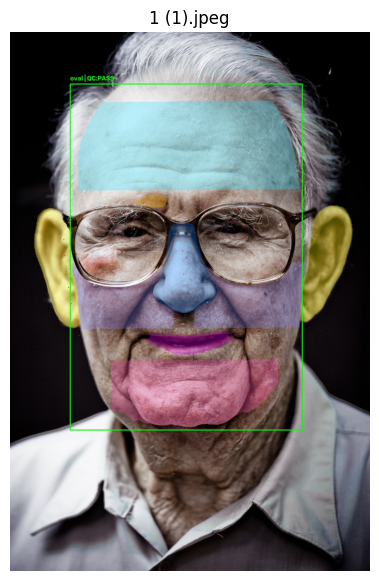

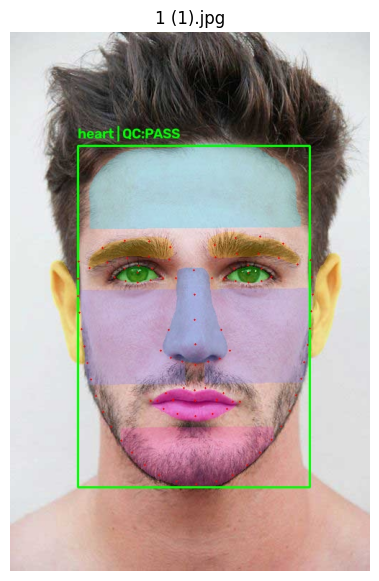

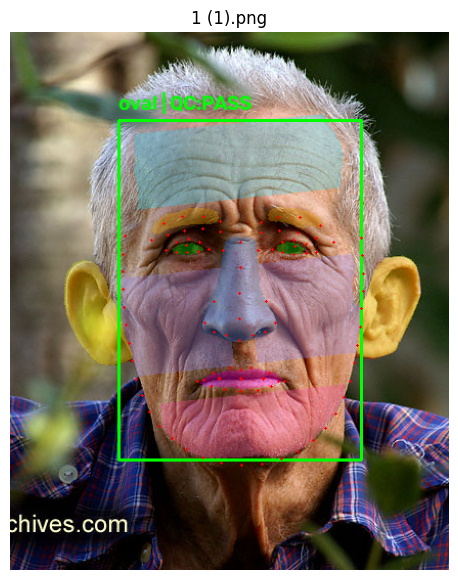

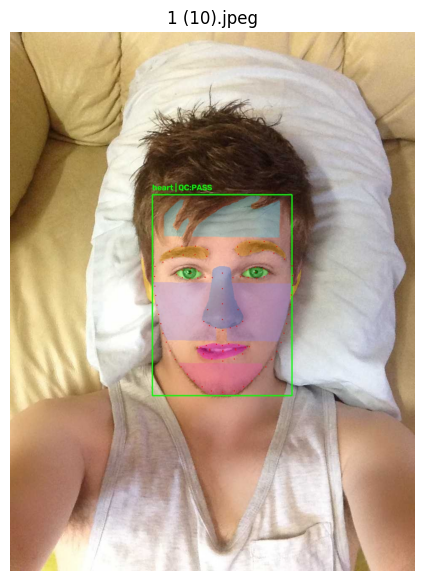

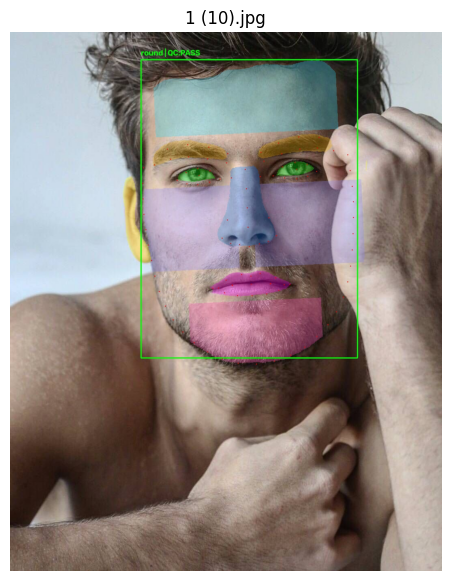

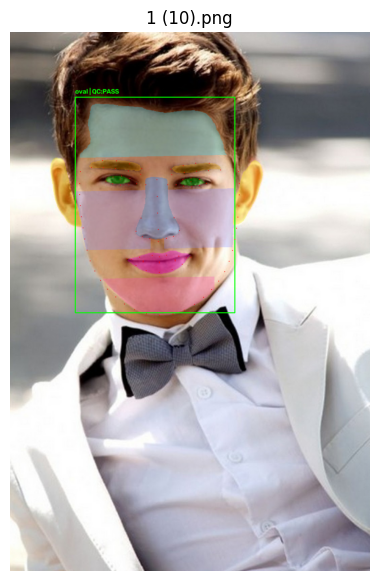

In [7]:
from IPython.display import display
import matplotlib.pyplot as plt

# ============================================================
# Inspect the final feature-only CSV
# ============================================================

if os.path.exists(CSV_PATH):
    df_check = pd.read_csv(CSV_PATH)

    print('Accepted rows:', len(df_check))
    print('Columns:', len(df_check.columns))

    if 'image_id' in df_check.columns:
        print('\nImage identifiers:')
        display(df_check[['image_id']].head(10))

    preview_cols = [
        'image_id',
        'roll_deg',
        'yaw_proxy',
        'face_height_width_ratio',
        'upper_to_cheek_ratio',
        'jaw_to_cheek_ratio',
        'region_forehead_area_ratio_face',
        'region_left_eye_area_ratio_face',
        'region_right_eye_area_ratio_face',
        'region_nose_area_ratio_face',
        'region_mouth_area_ratio_face',
        'region_chin_area_ratio_face',
        'region_left_cheek_area_ratio_face',
        'region_right_cheek_area_ratio_face',
        'inter_eye_distance_face_ratio',
        'nose_width_face_ratio',
        'mouth_width_face_ratio',
        'chin_width_face_ratio',
        'cheek_area_asymmetry',
    ]
    preview_cols = [c for c in preview_cols if c in df_check.columns]

    print('\nFeature preview:')
    display(df_check[preview_cols].head(10))

    # Verify that operational metadata did not leak into the final feature CSV.
    forbidden_prefixes = ('detection_', 'det_', 'bbox_', 'align_M_')
    forbidden_exact = {
        'image', 'relative_path', 'image_path', 'output_image_path',
        'output_mask_path', 'image_width', 'image_height',
        'num_faces_detected', 'qc_pass', 'qc_reasons',
        'was_recovered',
    }
    leaked = [
        c for c in df_check.columns
        if c in forbidden_exact or any(c.startswith(p) for p in forbidden_prefixes)
    ]
    print('\nOperational metadata leaked into final CSV:', leaked)


# ============================================================
# Error log remains separate from the feature CSV
# ============================================================

if os.path.exists(ERROR_CSV_PATH):
    err = pd.read_csv(ERROR_CSV_PATH)
    if len(err):
        print('\nTop error stages:')
        display(err['stage'].value_counts().rename('count').to_frame())
        display(err.head(10))


# ============================================================
# Show a few processed images
# Uses the output folder directly because output paths are intentionally
# not stored in the final feature CSV.
# ============================================================

sample_paths = [
    str(p)
    for p in Path(IMAGES_OUT_DIR).rglob('*')
    if p.is_file() and p.suffix.lower() in image_exts
][:6]

for p in sample_paths:
    im = cv2.imread(p)
    if im is None:
        continue

    im = cv2.cvtColor(im, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(7, 7))
    plt.imshow(im)
    plt.title(Path(p).name)
    plt.axis('off')
    plt.show()
